In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings

# Mute the specific UserWarning thrown by the ipykernel / pandasql bridge
warnings.filterwarnings("ignore", category=UserWarning, message=".*timedelta.*")


In [3]:
import sqlite3

# 1. Connect to  database 
conn = sqlite3.connect("hospital.db")
cursor = conn.cursor()

# 2. Read the .sql file
with open("create_hospital_db.sql", "r") as f:
    sql_script = f.read()

# 3. Execute the script (creates tables and inserts values)
cursor.executescript(sql_script)
conn.commit()

print("Tables created and data inserted successfully!")

# 4. (Optional) Test a quick query to verify it worked
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print("Tables in database:", cursor.fetchall())




Tables created and data inserted successfully!
Tables in database: [('payers',), ('patients',), ('procedures',), ('encounters',)]


In [4]:
import pandas as pd

In [5]:
payers_df = pd.read_sql("""SELECT * FROM payers""", conn)

In [6]:
patients_df = pd.read_sql("""SELECT * FROM patients""", conn)

In [7]:
procedures_df = pd.read_sql(""" SELECT * FROM procedures""", conn)

In [8]:
encounters_df = pd.read_sql("""SELECT * FROM encounters""", conn)

In [9]:
organizations_df = pd.read_csv("organizations.csv")

In [10]:
payers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   10 non-null     object
 1   NAME                 10 non-null     object
 2   ADDRESS              9 non-null      object
 3   CITY                 9 non-null      object
 4   STATE_HEADQUARTERED  9 non-null      object
 5   ZIP                  9 non-null      object
 6   PHONE                9 non-null      object
dtypes: object(7)
memory usage: 692.0+ bytes


In [11]:
procedures_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47701 entries, 0 to 47700
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   START              47701 non-null  object
 1   STOP               47701 non-null  object
 2   PATIENT            47701 non-null  object
 3   ENCOUNTER          47701 non-null  object
 4   CODE               47701 non-null  object
 5   DESCRIPTION        47701 non-null  object
 6   BASE_COST          47701 non-null  int64 
 7   REASONCODE         0 non-null      object
 8   REASONDESCRIPTION  0 non-null      object
dtypes: int64(1), object(8)
memory usage: 3.3+ MB


In [12]:
encounters_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27891 entries, 0 to 27890
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   27891 non-null  object 
 1   START                27891 non-null  object 
 2   STOP                 27891 non-null  object 
 3   PATIENT              27891 non-null  object 
 4   ORGANIZATION         27891 non-null  object 
 5   PAYER                27891 non-null  object 
 6   ENCOUNTERCLASS       27891 non-null  object 
 7   CODE                 27891 non-null  object 
 8   DESCRIPTION          27891 non-null  object 
 9   BASE_ENCOUNTER_COST  27891 non-null  float64
 10  TOTAL_CLAIM_COST     27891 non-null  float64
 11  PAYER_COVERAGE       27891 non-null  float64
 12  REASONCODE           8350 non-null   object 
 13  REASONDESCRIPTION    8350 non-null   object 
dtypes: float64(3), object(11)
memory usage: 3.0+ MB


In [13]:
patients_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Id          973 non-null    object 
 1   BIRTHDATE   973 non-null    object 
 2   DEATHDATE   0 non-null      object 
 3   PREFIX      973 non-null    object 
 4   FIRST       973 non-null    object 
 5   LAST        973 non-null    object 
 6   SUFFIX      0 non-null      object 
 7   MAIDEN      973 non-null    object 
 8   MARITAL     973 non-null    object 
 9   RACE        973 non-null    object 
 10  ETHNICITY   973 non-null    object 
 11  GENDER      973 non-null    object 
 12  BIRTHPLACE  973 non-null    object 
 13  ADDRESS     973 non-null    object 
 14  CITY        973 non-null    object 
 15  STATE       973 non-null    object 
 16  COUNTY      973 non-null    object 
 17  ZIP         973 non-null    object 
 18  LAT         973 non-null    float64
 19  LON         973 non-null    f

In [14]:
organizations_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Id       1 non-null      object 
 1   NAME     1 non-null      object 
 2   ADDRESS  1 non-null      object 
 3   CITY     1 non-null      object 
 4   STATE    1 non-null      object 
 5   ZIP      1 non-null      int64  
 6   LAT      1 non-null      float64
 7   LON      1 non-null      float64
dtypes: float64(2), int64(1), object(5)
memory usage: 196.0+ bytes


In [15]:
from pandasql import sqldf

pysqldf = lambda q: sqldf(q, globals())

In [16]:
q = """
SELECT *
FROM encounters_df
"""
pysqldf(q).head()

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,None,None
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,None,None
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,None,None
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,None,None
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004,Hyperlipidemia


In [17]:
q = """
SELECT *
FROM patients_df
LIMIT 5
"""
pysqldf(q)

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,None,Mrs.,Nikita578,Erdman779,None,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,02186,42.290937,-70.975503
1,6e5ae27c-8038-7988-e2c0-25a103f01bfa,1940-02-19,None,Mr.,Zane918,Hodkiewicz467,None,,M,white,nonhispanic,M,Brookline Massachusetts US,747 Conn Throughway,Boston,Massachusetts,Suffolk County,02135,42.308831,-71.063162
2,8123d076-0886-9007-e956-d5864aa121a7,1958-06-04,None,Mr.,Quinn173,Marquardt819,None,,M,white,nonhispanic,M,Gardner Massachusetts US,816 Okuneva Extension Apt 91,Quincy,Massachusetts,Norfolk County,02170,42.265177,-70.967085
3,770518e4-6133-648e-60c9-071eb2f0e2ce,1928-12-25,None,Mr.,Abel832,Smitham825,None,,M,white,hispanic,M,Randolph Massachusetts US,127 Cole Way Unit 95,Boston,Massachusetts,Suffolk County,02118,42.334304,-71.066801
4,f96addf5-81b9-0aab-7855-d208d3d352c5,1928-12-25,None,Mr.,Edwin773,Labadie908,None,,M,white,hispanic,M,Stow Massachusetts US,976 Ziemann Gateway,Boston,Massachusetts,Suffolk County,02125,42.346771,-71.058813


In [18]:
q = """SELECT * FROM procedures_df"""
pysqldf(q).head()

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,None,None
1,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,None,None
2,2011-01-04 14:49:55,2011-01-04 15:04:55,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (p...,11620,None,None
3,2011-01-05 04:02:09,2011-01-05 04:17:09,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,None,None
4,2011-01-05 12:58:36,2011-01-05 16:42:36,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,None,None


In [19]:
#check for duplicates in patients table
q = """
SELECT Id, COUNT(*)
FROM patients_df
GROUP BY Id
HAVING COUNT(*) > 1
"""
pysqldf(q)

,Id,COUNT(*)


In [20]:
#check for duplicate encounters_df
q = """
SELECT Id, COUNT(*)
FROM encounters_df
GROUP BY Id
HAVING COUNT(*) > 1
"""
pysqldf(q)

,Id,COUNT(*)


### Inspect the dataset results:
#### Encounters table
* Related to the patients table using Patient as foreign key
* Related to Organizations using Organization as foreign key
* Related to the Payers table using Payer as foreign key 
* Base encounter cost- Is like consultation fee
* Total_Claim_Cost - consultation + cost of other treatment and equipments
* Converted START and STOP columns to datetime.
##### Patients table
* Marital status restricted to only married and single, 
* Gender limited to Male and Female, in health sector we have other genders like intersex
#### Procedures table
* has no unique identifier like id 
* Related to the patients table using Patient as a Foreign key
* Related to the encounters table using Encounter as a Foreign key
* REASONCODE AND REASONCOLUMNS are completely empty giving us hard time to discovering why a procedure was performed.

## Encounters Analysis
### Answers the following:
* How have encounter volumes changed over time? 
* Which encounter classes account for the largest proportion of recorded encounters?
* How do total claim costs vary across encounter classes? 
* How much payer coverage is recorded, and how many encounters have zero recorded payer  coverage? 
* Revenue generated per encounter class

In [21]:
encounters_df['START'] = pd.to_datetime(encounters_df['START'])
encounters_df['STOP'] = pd.to_datetime(encounters_df['STOP'])

In [22]:
encounters_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27891 entries, 0 to 27890
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Id                   27891 non-null  object        
 1   START                27891 non-null  datetime64[ns]
 2   STOP                 27891 non-null  datetime64[ns]
 3   PATIENT              27891 non-null  object        
 4   ORGANIZATION         27891 non-null  object        
 5   PAYER                27891 non-null  object        
 6   ENCOUNTERCLASS       27891 non-null  object        
 7   CODE                 27891 non-null  object        
 8   DESCRIPTION          27891 non-null  object        
 9   BASE_ENCOUNTER_COST  27891 non-null  float64       
 10  TOTAL_CLAIM_COST     27891 non-null  float64       
 11  PAYER_COVERAGE       27891 non-null  float64       
 12  REASONCODE           8350 non-null   object        
 13  REASONDESCRIPTION    8350 non-n

In [23]:
#create a duration column 
encounters_df['DURATION'] = encounters_df['STOP'] - encounters_df['START']


In [24]:
average_duration = encounters_df['DURATION'].mean()
highest_duration = encounters_df['DURATION'].max()
lowest_duration = encounters_df['DURATION'].min()

print(f"The average duration for encounter:{average_duration}")
print(f"The highest encounter duration lasted for {highest_duration}")
print(f"The shortest encounter duration lasted for {lowest_duration}")

The average duration for encounter:0 days 07:15:57.580904234
The highest encounter duration lasted for 1872 days 02:00:00
The shortest encounter duration lasted for 0 days 00:15:00


That average of 7 hours and 15 minutes sounds incredibly standard for healthcare encounters!
However, that maximum duration of 1,872 days (which is over 5 years!) is a massive outlier. In healthcare data, a multi-year duration like this usually happens because of one of three things:
1. Administrative Error: Someone forgot to officially "close" or "discharge" the patient encounter in the system for years.
2. Chronic/Ongoing Care: It represents an ongoing billing cycle or tracking code for a long-term condition rather than a single visit.
3. Data entry typo: The STOP year might have been typed incorrectly (e.g., typing 2021 instead of 2011).


In [25]:
# Find the 'outlier'
outlier = encounters_df[encounters_df['DURATION'] == encounters_df['DURATION'].max()]
#print(outlier[['START', 'STOP', 'ENCOUNTERCLASS', 'DESCRIPTION']])
outlier

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION,DURATION
9704,fc2c2add-0b55-e300-5cea-8f43044eb330,2014-12-17 11:49:08,2020-02-01 13:49:08,5d47b9ac-3f37-f400-1747-c6c6f92130aa,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,390906007,Follow-up encounter (procedure),85.55,85.55,0.0,None,None,1872 days 02:00:00


In [26]:
# 1. Convert DURATION to total minutes
encounters_df['DURATION_MINUTES'] = encounters_df['DURATION'].dt.total_seconds() / 60


In [27]:
#average duration per encounter
q = """
SELECT ENCOUNTERCLASS, AVG(DURATION_MINUTES)
FROM encounters_df
GROUP BY ENCOUNTERCLASS
"""
pysqldf(q)

,ENCOUNTERCLASS,AVG(DURATION_MINUTES)
0,ambulatory,568.765058
1,emergency,92.505319
2,inpatient,2210.495154
3,outpatient,352.552317
4,urgentcare,15.000000
5,wellness,15.000000


In [28]:
summary = encounters_df.groupby('ENCOUNTERCLASS')['DURATION_MINUTES'].agg(['mean', 'median', 'count'])
summary

,mean,median,count
ENCOUNTERCLASS,,,
ambulatory,568.765058,15.0,12537
emergency,92.505319,60.0,2322
inpatient,2210.495154,1440.0,1135
outpatient,352.552317,15.0,6300
urgentcare,15.000000,15.0,3666
wellness,15.000000,15.0,1931


In [29]:
encounters_df['START_YEAR'] = encounters_df['START'].dt.year
encounters_df['STOP_YEAR'] = encounters_df['STOP'].dt.year

In [30]:
#amount generated per encounter
q = """
SELECT ENCOUNTERCLASS, SUM(BASE_ENCOUNTER_COST) AS consultation_fee, SUM(TOTAL_CLAIM_COST) AS medical_bill
FROM encounters_df
GROUP BY ENCOUNTERCLASS
ORDER BY consultation_fee DESC, medical_bill DESC
"""
pysqldf(q)

,ENCOUNTERCLASS,consultation_fee,medical_bill
0,ambulatory,1325525.43,36283440.84
1,outpatient,661750.59,14094967.12
2,urgentcare,522698.28,23349349.96
3,emergency,337266.57,10750051.53
4,wellness,264160.80,8227431.73
5,inpatient,129019.73,8809134.34


Ambulatory and outpatient classes generate the highest total revenue for both consultation fees and total medical bills, mostly because they have a massive volume of patients (over 18,000 encounters combined).

In [31]:
# amount generated PER SINGLE encounter
q = """
SELECT 
    ENCOUNTERCLASS, 
    COUNT(*) AS total_visits,
    ROUND(AVG(BASE_ENCOUNTER_COST), 2) AS avg_consultation_fee, 
    ROUND(AVG(TOTAL_CLAIM_COST), 2) AS avg_medical_bill
FROM encounters_df
GROUP BY ENCOUNTERCLASS
ORDER BY avg_medical_bill DESC
"""
pysqldf(q)

,ENCOUNTERCLASS,total_visits,avg_consultation_fee,avg_medical_bill
0,inpatient,1135,113.67,7761.35
1,urgentcare,3666,142.58,6369.16
2,emergency,2322,145.25,4629.65
3,wellness,1931,136.80,4260.71
4,ambulatory,12537,105.73,2894.11
5,outpatient,6300,105.04,2237.30


Even though Ambulatory brings in the most total money because of its massive volume (12,537 visits), Inpatient visits are by far the most expensive single encounters, with an average medical bill of 7,761.35 per stay.

#### Interesting Discoveries:
* The Inpatient Premium: Inpatient visits have the lowest consultation fee (113.67) but the highest overall bill (7,761.35). This makes complete sense because the bulk of the cost comes from room charges, overnight nursing, and intensive hospital resources rather than just the doctor's initial fee.
* Urgent Care vs. Emergency: Urgent Care visits actually average a higher medical bill (6,369.16) than Emergency room visits (4,629.65) in this dataset. In the real world, ER visits are usually more expensive, meaning the dataset might have some unique high-cost procedures or specific tests heavily bundled into Urgent Care.
* Wellness Value: A typical wellness checkup averaging a 4,260.71 total claim cost suggests these records include comprehensive annual physicals, extensive screening labs, or preventative imaging bundled into the preventative care track

/var/folders/th/xsvfrj3d3bvffr_vt4sx1f7m0000gn/T/ipykernel_10380/4150456574.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_revenue, x='ENCOUNTERCLASS', y='Total_Revenue', ax=axes[0], palette='Blues_r', order=df_revenue.sort_values('Total_Revenue', ascending=False)['ENCOUNTERCLASS'])
/var/folders/th/xsvfrj3d3bvffr_vt4sx1f7m0000gn/T/ipykernel_10380/4150456574.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_revenue, x='ENCOUNTERCLASS', y='Avg_Bill', ax=axes[1], palette='Oranges_r', order=df_revenue.sort_values('Avg_Bill', ascending=False)['ENCOUNTERCLASS'])


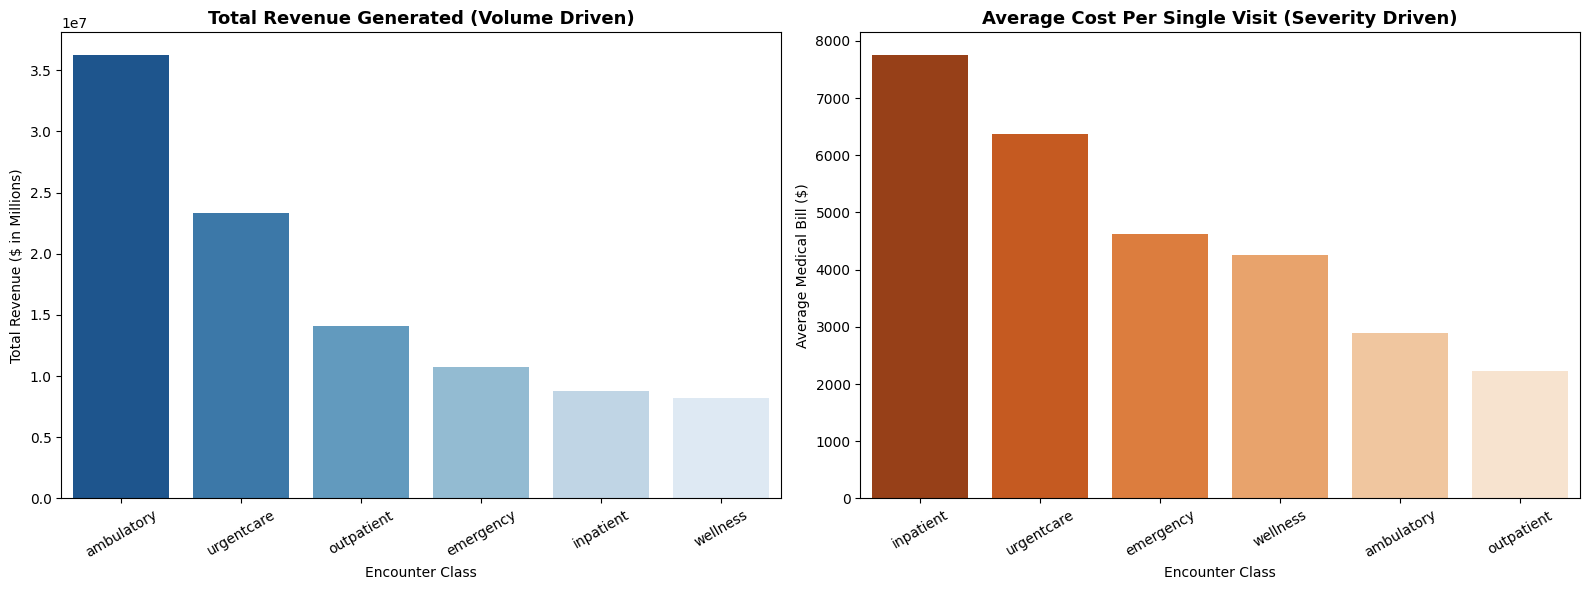

In [32]:
#  get both the totals and the averages using pandas for easy plotting
df_revenue = encounters_df.groupby('ENCOUNTERCLASS').agg(
    Total_Revenue=('TOTAL_CLAIM_COST', 'sum'),
    Avg_Bill=('TOTAL_CLAIM_COST', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Total Revenue (Volume Driven)
sns.barplot(data=df_revenue, x='ENCOUNTERCLASS', y='Total_Revenue', ax=axes[0], palette='Blues_r', order=df_revenue.sort_values('Total_Revenue', ascending=False)['ENCOUNTERCLASS'])
axes[0].set_title('Total Revenue Generated (Volume Driven)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Total Revenue ($ in Millions)')
axes[0].set_xlabel('Encounter Class')
axes[0].tick_params(axis='x', rotation=30)

# Plot 2: Average Medical Bill (Severity Driven)
sns.barplot(data=df_revenue, x='ENCOUNTERCLASS', y='Avg_Bill', ax=axes[1], palette='Oranges_r', order=df_revenue.sort_values('Avg_Bill', ascending=False)['ENCOUNTERCLASS'])
axes[1].set_title('Average Cost Per Single Visit (Severity Driven)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Average Medical Bill ($)')
axes[1].set_xlabel('Encounter Class')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

1. The Volume Driver (Left): Ambulatory out in front, generating over $36.2M in total claims. This happens because it has the largest patient base (\(12,537\) visits).
2. The Severity Driver (Right): Inpatient shoot straight to the top of the chart. Even though it generates a lower overall sum because it has fewer patients (\(1,135\) visits), the individual intensity of overnight stays makes it overwhelmingly the most expensive single encounter type.

In [33]:
#encounter volumes per year
encounters_df['START_YEAR'].value_counts().sort_index()

START_YEAR
2011    1336
2012    2106
2013    2495
2014    3885
2015    2469
2016    2451
2017    2360
2018    2292
2019    2228
2020    2519
2021    3530
2022     220
Name: count, dtype: int64

<Axes: xlabel='START_YEAR'>

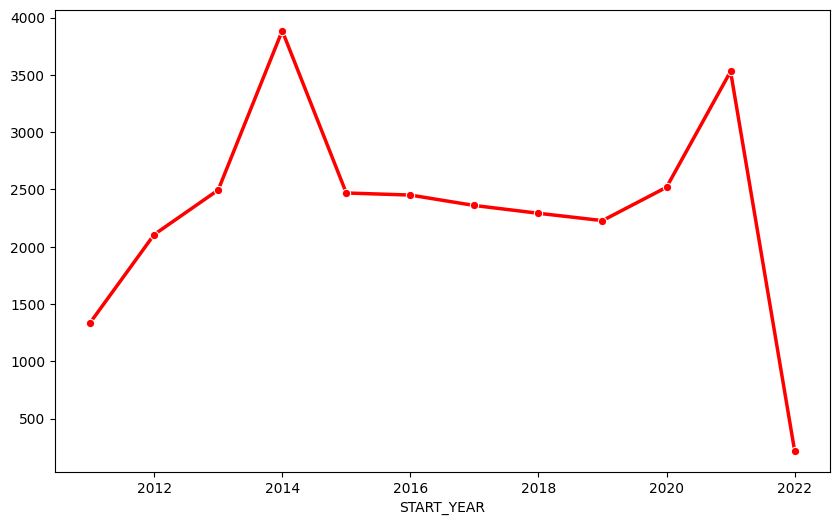

In [34]:
plt.figure(figsize=(10, 6))
yearly_counts = encounters_df['START_YEAR'].value_counts().sort_index()
sns.lineplot(x=yearly_counts.index,  y=yearly_counts.values, marker='o', linewidth=2.5, color='red')


Key Observations:
* The 2014 Peak (3,885 visits): There is a huge surge in volume up to 2014, followed by a noticeable drop-off in 2015. In synthetic healthcare datasets a spike in a specific year often correlates with a major policy change, a regional disease model outbreak simulation, or a large batch of patient records being initialized.
* The 2021 Rebound (3,530 visits): Volume remains relatively flat and steady between 2015 and 2019, followed by a sudden jump in 2021.
* The 2022 Drop (220 visits): This very low number usually means the data snapshot was taken early in the year 2022 (likely around January or February), so the year is incomplete.


In [35]:
# Calculate total visits and total medical bills per year
yearly_financials = encounters_df.groupby('START_YEAR').agg(
    Total_Visits=('TOTAL_CLAIM_COST', 'count'),
    Total_Revenue_Millions=('TOTAL_CLAIM_COST', lambda x: round(x.sum() / 1_000_000, 2))
)

yearly_financials

,Total_Visits,Total_Revenue_Millions
START_YEAR,,
2011,1336,4.41
2012,2106,9.06
2013,2495,10.11
2014,3885,12.01
2015,2469,10.12
2016,2451,8.39
2017,2360,9.60
2018,2292,8.75
2019,2228,8.92


In [36]:
#total revenue generated by year
q = """
SELECT START_YEAR, SUM(TOTAL_CLAIM_COST) AS total_revenue, COUNT(Id) AS total_visits
FROM encounters_df
GROUP BY START_YEAR
ORDER BY total_revenue DESC
"""
pysqldf(q)

,START_YEAR,total_revenue,total_visits
0,2014,12011662.17,3885
1,2020,10294077.96,2519
2,2015,10124652.89,2469
3,2013,10105272.87,2495
4,2017,9596894.47,2360
5,2021,9177232.00,3530
6,2012,9058314.10,2106
7,2019,8915338.78,2228
8,2018,8746818.37,2292
9,2016,8386701.12,2451


- Even though 2014 had roughly 1,300 more patients, 2020 was nearly as profitable.2021, had a massive volume of 3,530 visits but brought in less revenue ($9.17M) than 2020.
- This strongly suggests that in 2020, the severity or type of encounters shifted dramatically toward high-cost treatments (like intense inpatient stays or critical care), which is completely consistent with real-world healthcare trends during the onset of the COVID-19 pandemic.

In [37]:
q = """
SELECT 
    START_YEAR, 
    COUNT(Id) AS total_visits,
    ROUND(SUM(TOTAL_CLAIM_COST), 2) AS total_revenue,
    ROUND(AVG(TOTAL_CLAIM_COST), 2) AS avg_cost_per_visit
FROM encounters_df
GROUP BY START_YEAR
ORDER BY START_YEAR ASC
"""
pysqldf(q)

,START_YEAR,total_visits,total_revenue,avg_cost_per_visit
0,2011,1336,4405936.73,3297.86
1,2012,2106,9058314.10,4301.19
2,2013,2495,10105272.87,4050.21
3,2014,3885,12011662.17,3091.80
4,2015,2469,10124652.89,4100.71
5,2016,2451,8386701.12,3421.75
6,2017,2360,9596894.47,4066.48
7,2018,2292,8746818.37,3816.24
8,2019,2228,8915338.78,4001.50
9,2020,2519,10294077.96,4086.57


Look at the direct contrast between those two years:
* 2020: The average visit cost $4,086.57

* 2021: The average visit cost plummeted to 2,599.78 (the lowest average in the entire dataset)

Even though 2021 brought an extra 1,011 patients through the doors, the total revenue actually dropped by more than a million dollars because the average cost per single encounter collapsed by over $1,480.

What explains this sudden drop in 2021?

When a healthcare system sees patient volume spike while average costs drop dramatically, it almost always means the mix of encounters changed. Instead of expensive overnight hospitalizations (inpatient), the system likely processed a massive influx of quick, cheap visits—such as routine checkups (wellness) or vaccine appointments.

In [38]:
# Create a cross-tabulation of Year vs Encounter Class to see the patient mix
encounter_mix = pd.crosstab(encounters_df['START_YEAR'], encounters_df['ENCOUNTERCLASS'])
encounter_mix

ENCOUNTERCLASS,ambulatory,emergency,inpatient,outpatient,urgentcare,wellness
START_YEAR,,,,,,
2011,667,55,83,327,30,174
2012,895,183,93,444,299,192
2013,1106,225,134,485,359,186
2014,2341,216,118,694,327,189
2015,1073,228,111,506,380,171
2016,1073,250,124,481,341,182
2017,987,218,126,475,385,169
2018,933,247,81,480,377,174
2019,846,227,134,456,397,168


This cross-tabulation completely solves the mystery Look at the row for 2021:
Outpatient visits exploded from 497 in 2020 to 1,418 in 2021—nearly tripling in volume! At the same time,inpatient stays (the most expensive encounter type) dropped to their lowest point yet, with only 55 visits.
Because the facility flooded with almost a thousand extra quick, low-cost outpatient visits while cutting back on expensive overnight hospital stays, the overall average cost per visit plummeted even though the buildings were busier than ever.

Another interesting finding:

Look at the 2014 peak we noticed earlier. That surge was driven almost entirely by ambulatory visits, which jumped to 2,341 that year before cutting back in half down to 1,073 the following year.

In [39]:
#total amount covered by insurance
q = """
SELECT SUM(PAYER_COVERAGE) as insurance_coverage
FROM encounters_df
"""
pysqldf(q)

,insurance_coverage
0,31097506.99


In [40]:
#total amount covered by insurance per encounter class
q = """
SELECT ENCOUNTERCLASS, SUM(PAYER_COVERAGE) as insurance_coverage
FROM encounters_df
GROUP BY ENCOUNTERCLASS
ORDER BY insurance_coverage DESC
"""
pysqldf(q)

,ENCOUNTERCLASS,insurance_coverage
0,ambulatory,12903495.75
1,wellness,4421749.94
2,outpatient,3777758.35
3,inpatient,3688764.95
4,emergency,3246828.27
5,urgentcare,3058909.73


In [41]:
encounters_df['OUT_OF_POCKET'] = encounters_df['TOTAL_CLAIM_COST'] - encounters_df['PAYER_COVERAGE']

In [42]:
encounters_df

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION,DURATION,DURATION_MINUTES,START_YEAR,STOP_YEAR,OUT_OF_POCKET
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,None,None,0 days 03:32:00,212.00,2011,2011,1018.02
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,None,None,0 days 00:17:03,17.05,2011,2011,2619.36
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,None,None,0 days 00:15:00,15.00,2011,2011,156.32
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,None,None,0 days 00:15:00,15.00,2011,2011,1784.24
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004,Hyperlipidemia,0 days 00:15:00,15.00,2011,2011,234.72
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27886,917bb534-2ed3-e1f5-ac27-74f314d19c63,2022-01-29 11:42:06,2022-01-29 11:57:06,0c122290-8c15-77ac-b418-2fea4e8a8e6a,d78e84ec-30aa-3bba-a33a-f29a3a454662,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,outpatient,185349003,Encounter for check up (procedure),85.55,85.55,24.27,None,None,0 days 00:15:00,15.00,2022,2022,61.28
27887,07710480-9d6b-9c9b-87c3-c1d54df4069d,2022-01-29 20:12:53,2022-01-29 20:27:53,20a4bc24-6b69-2f5c-dc74-1df390cae25b,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,urgentcare,702927004,Urgent care clinic (procedure),142.58,10588.34,8438.67,None,None,0 days 00:15:00,15.00,2022,2022,2149.67
27888,01b57f06-cebe-a3e4-4423-a796ffb0c35d,2022-01-29 20:35:37,2022-01-29 20:50:37,ff1b3c26-53a6-4590-ce79-a3f7269274ea,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,424619006,Prenatal visit,142.58,11984.29,0.00,72892002,Normal pregnancy,0 days 00:15:00,15.00,2022,2022,11984.29
27889,7d435668-0813-eb3b-0f26-cb741fb39561,2022-01-29 20:35:37,2022-01-29 20:50:37,ff1b3c26-53a6-4590-ce79-a3f7269274ea,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,408.80,0.00,None,None,0 days 00:15:00,15.00,2022,2022,408.80


In [43]:
#coverage per visit
q = """
SELECT 
    ENCOUNTERCLASS,
    COUNT(*) AS total_visits,
    ROUND(AVG(TOTAL_CLAIM_COST), 2) AS avg_bill,
    ROUND(AVG(PAYER_COVERAGE), 2) AS avg_insurance_paid,
    ROUND(AVG(TOTAL_CLAIM_COST - PAYER_COVERAGE), 2) AS avg_patient_pays,
    ROUND((SUM(PAYER_COVERAGE) / SUM(TOTAL_CLAIM_COST)) * 100, 2) AS total_coverage_percentage
FROM encounters_df
GROUP BY ENCOUNTERCLASS
ORDER BY total_coverage_percentage DESC
"""
pysqldf(q)


,ENCOUNTERCLASS,total_visits,avg_bill,avg_insurance_paid,avg_patient_pays,total_coverage_percentage
0,wellness,1931,4260.71,2289.88,1970.83,53.74
1,inpatient,1135,7761.35,3250.01,4511.34,41.87
2,ambulatory,12537,2894.11,1029.23,1864.88,35.56
3,emergency,2322,4629.65,1398.29,3231.36,30.20
4,outpatient,6300,2237.30,599.64,1637.65,26.80
5,urgentcare,3666,6369.16,834.40,5534.76,13.10


- The calculation reveals that urgentcare leaves individual patients with the highest out-of-pocket burden, forcing them to pay an average of 5,534.76 out of pocket per single visit. This is because insurance only kicks in to cover a very low 13.10% of the bill.
- Meanwhile, inpatient stays have the second highest average patient payout ($4,511.34), though insurance does cover a much higher portion of it overall (41.87%).

Key Takeaways:

• The Urgent Care Trap: An urgent care visit carries a steep average bill ($6,369.16), but because the coverage percentage is so low, it results in the absolute worst financial outcome for the patient.
• Wellness Checkups: This is the only encounter class where insurance pays for more than half of the visit (53.74%), leaving the patient with the lowest average bill of 1,970.83.

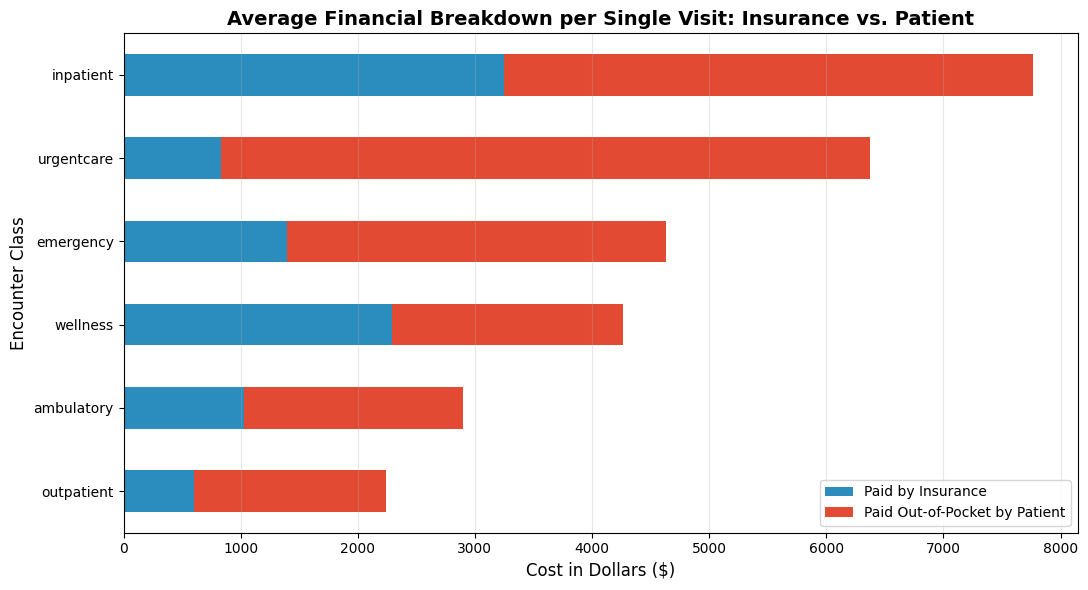

In [44]:
# 1. Calculate the exact columns needed
encounters_df['OUT_OF_POCKET'] = encounters_df['TOTAL_CLAIM_COST'] - encounters_df['PAYER_COVERAGE']

# 2. Group by class and calculate the averages per individual visit
financial_averages = encounters_df.groupby('ENCOUNTERCLASS').agg(
    avg_insurance_paid=('PAYER_COVERAGE', 'mean'),
    avg_patient_pays=('OUT_OF_POCKET', 'mean')
).reset_index()

# Sort by the total average bill so the longest bars appear at the top
financial_averages['total_bill'] = financial_averages['avg_insurance_paid'] + financial_averages['avg_patient_pays']
financial_averages = financial_averages.sort_values('total_bill', ascending=True) # Changed to True so largest is at the top of a horizontal chart

# Set ENCOUNTERCLASS as the index and select only the two segments to stack
plot_data = financial_averages.set_index('ENCOUNTERCLASS')[['avg_insurance_paid', 'avg_patient_pays']]

# Plot the clean, isolated segments
plot_data.plot(kind='barh', stacked=True, figsize=(11, 6), color=['#2b8cbe', '#e34a33'])

# 3. Add titles and clean up the chart
plt.title('Average Financial Breakdown per Single Visit: Insurance vs. Patient', fontsize=14, fontweight='bold')
plt.xlabel('Cost in Dollars ($)', fontsize=12)
plt.ylabel('Encounter Class', fontsize=12)
plt.legend(['Paid by Insurance', 'Paid Out-of-Pocket by Patient'], loc='lower right')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
#how many encounters have zero recorded payer  coverage? 
q = """
SELECT COUNT(*) AS total_zero_payer_coverage
FROM encounters_df
WHERE PAYER_COVERAGE = 0
"""
pysqldf(q)

,total_zero_payer_coverage
0,13586


That is a massive number! Out of 27,891 total encounters, 13,586 of them—nearly 49%—have absolutely zero insurance coverage recorded.
When nearly half of a healthcare database has zero payer coverage, it usually points to one of two structural reasons:
1. Uninsured Patients / Self-Pay: A massive portion of your patient base is completely uninsured, meaning they have to pay 100% of their bills out of pocket.
2. Denials or Pre-Adjudicated Data: These might be claims that insurance completely denied, or rows representing "open" encounters where the insurance claim simply hasn't been submitted or processed yet.

#### Which Encounter Classes Have No Coverage?
To understand why this is happening, we should see which encounter types are driving these zero-coverage rows. For example, if they are mostly wellness visits, it's weird; if they are mostly urgentcare, it explains why urgent care has that abysmal 13% coverage rate we found earlier!

In [46]:
q = """
SELECT 
    ENCOUNTERCLASS,
    COUNT(*) AS zero_coverage_visits,
    ROUND((COUNT(*) * 100.0 / (SELECT COUNT(*) FROM encounters_df WHERE PAYER_COVERAGE = 0)), 2) AS pct_of_all_zeros
FROM encounters_df
WHERE PAYER_COVERAGE = 0
GROUP BY ENCOUNTERCLASS
ORDER BY zero_coverage_visits DESC
"""
pysqldf(q)

,ENCOUNTERCLASS,zero_coverage_visits,pct_of_all_zeros
0,ambulatory,6503,47.87
1,outpatient,3302,24.30
2,urgentcare,1678,12.35
3,wellness,793,5.84
4,emergency,759,5.59
5,inpatient,551,4.06


In [47]:
# 1. Count total visits per class
total_counts = encounters_df['ENCOUNTERCLASS'].value_counts()

# 2. Count zero coverage visits per class
zero_counts = encounters_df[encounters_df['PAYER_COVERAGE'] == 0]['ENCOUNTERCLASS'].value_counts()

# 3. Combine and calculate the percentage
uncovered_ratio = pd.DataFrame({
    'Total Visits': total_counts,
    'Zero Coverage Visits': zero_counts,
    '% of Class Uncovered': round((zero_counts / total_counts) * 100, 2)
}).sort_values('% of Class Uncovered', ascending=False)

uncovered_ratio

,Total Visits,Zero Coverage Visits,% of Class Uncovered
ENCOUNTERCLASS,,,
outpatient,6300,3302,52.41
ambulatory,12537,6503,51.87
inpatient,1135,551,48.55
urgentcare,3666,1678,45.77
wellness,1931,793,41.07
emergency,2322,759,32.69


Almost half of every single departments visits receive absolutely zero financial coverage from insurance.
Look at how remarkably consistent this "uncovered" rate is across the board:
• outpatient and ambulatory lead the pack: Over 52% of all outpatient and 51.8% of ambulatory patients get completely left behind by insurance.
• inpatient is highly vulnerable: Even for major overnight hospital stays, 48.55% of patients receive $0 in insurance coverage. Because an average inpatient bill is $7,761.35, these individuals are taking on massive personal debt.
• emergency is the safest bet: Emergency visits have the best coverage rate, but even then, nearly 1 in 3 emergency visits (32.69%) goes completely uncovered.

#### What does this pattern mean?

When an insurance gap is this evenly distributed across routine checkups, emergency surgeries, and outpatient visits, it usually means the dataset features a massive population of totally uninsured (self-pay) patients.

## Payers Analysis

In [48]:
#unique insurance covers
q = """
SELECT DISTINCT(NAME)
FROM payers_df
"""
pysqldf(q)

,NAME
0,Dual Eligible
1,Medicare
2,Medicaid
3,Humana
4,Blue Cross Blue Shield
5,UnitedHealthcare
6,Aetna
7,Cigna Health
8,Anthem
9,NO_INSURANCE


In [49]:
#join enounters_df and payers_df
encounters_payers_df = encounters_df.merge(payers_df, left_on='PAYER', right_on='Id', how='inner')
encounters_payers_df.head()

,Id_x,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,...,START_YEAR,STOP_YEAR,OUT_OF_POCKET,Id_y,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,...,2011,2011,1018.02,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,None,None,None,None,None
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,...,2011,2011,2619.36,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,None,None,None,None,None
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,...,2011,2011,156.32,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244,1-800-633-4227
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,...,2011,2011,1784.24,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,None,None,None,None,None
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,...,2011,2011,234.72,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204,1-800-331-1476


In [50]:
unmasked_zeros = encounters_payers_df[encounters_payers_df['PAYER_COVERAGE'] == 0].groupby('NAME').size().reset_index(name='zero_coverage_count')

# Sort to see the top culprits at the top
unmasked_zeros = unmasked_zeros.sort_values('zero_coverage_count', ascending=False)
print(unmasked_zeros)

                     NAME  zero_coverage_count
8            NO_INSURANCE                 8807
5                  Humana                 1038
0                   Aetna                  898
9        UnitedHealthcare                  820
3            Cigna Health                  790
1                  Anthem                  704
2  Blue Cross Blue Shield                  336
4           Dual Eligible                  127
7                Medicare                   61
6                Medicaid                    5


#### Let's Find the True "Denial Rate" per Insurance Company

To see which commercial insurer leaves their customers hanging the most often, we shouldn't look at totals alone (since bigger companies naturally have more visits). Instead, we should find out what percentage of their total claims get a $0 payout.

In [51]:
q = """
SELECT 
    NAME,
    COUNT(*) AS total_submitted_visits,
    SUM(CASE WHEN PAYER_COVERAGE = 0 THEN 1 ELSE 0 END) AS zero_coverage_visits,
    ROUND((SUM(CASE WHEN PAYER_COVERAGE = 0 THEN 1 ELSE 0 END) * 100.0 / COUNT(*)), 2) AS zero_payout_rate_pct
FROM encounters_payers_df
GROUP BY NAME
ORDER BY zero_payout_rate_pct DESC
"""
pysqldf(q)

,NAME,total_submitted_visits,zero_coverage_visits,zero_payout_rate_pct
0,NO_INSURANCE,8807,8807,100.00
1,Anthem,704,704,100.00
2,Cigna Health,809,790,97.65
3,Aetna,936,898,95.94
4,Humana,1084,1038,95.76
5,UnitedHealthcare,900,820,91.11
6,Blue Cross Blue Shield,925,336,36.32
7,Dual Eligible,912,127,13.93
8,Medicare,11371,61,0.54
9,Medicaid,1443,5,0.35


#### Major Insurance Findings:

- The 100% Club [1]: Anthem has a 100% zero-payout rate [1]. Every single one of its 704 submitted encounters resulted in a $0 payment to the hospital.
- The Near-Total Deflection Group [1]: Cigna Health (97.65%), Aetna (95.94%), Humana (95.76%), and UnitedHealthcare (91.11%) are rejecting or deflecting almost every single medical bill. If a patient has one of these plans, they are almost guaranteed to be stuck with the entire bill out of pocket.
- The "Real" Insurers [1]: Blue Cross Blue Shield is the only commercial plan acting traditionally, covering roughly 64% of its visits. Government-backed programs like Medicare (0.54% zero-payout rate) and Medicaid (0.35%) almost always pay out something on a patient's claim.


#### Let's Find Out Exactly What They Are Refusing to Pay For

To understand why commercial plans are paying $0 over 90% of the time, we should check which types of encounters they are backing out on. For example, are they paying for inpatient stays but completely rejecting ambulatory follow-ups?
Let's cross-tabulate Insurance Company Name against Encounter Class specifically for the zero-coverage visits:

In [52]:
# Filter for only commercial insurance zero-payout rows (excluding NO_INSURANCE)
commercial_zeros = encounters_payers_df[
    (encounters_payers_df['PAYER_COVERAGE'] == 0) & 
    (encounters_payers_df['NAME'] != 'NO_INSURANCE')
]

# Create a clean cross-tabulation of Payer Name vs Encounter Class
denial_matrix = pd.crosstab(commercial_zeros['NAME'], commercial_zeros['ENCOUNTERCLASS'])
denial_matrix

ENCOUNTERCLASS,ambulatory,emergency,inpatient,outpatient,urgentcare,wellness
NAME,,,,,,
Aetna,400,36,42,310,36,74
Anthem,313,35,14,261,15,66
Blue Cross Blue Shield,131,18,6,134,25,22
Cigna Health,319,36,21,287,28,99
Dual Eligible,70,0,3,53,0,1
Humana,474,47,63,321,44,89
Medicaid,0,2,1,0,0,2
Medicare,2,2,20,0,0,37
UnitedHealthcare,341,28,49,305,31,66


The cross-tabulation clearly shows that ambulatory and outpatient procedures dominate the zero-coverage pile across all major commercial insurance providers.
Looking closely at companies like Aetna, Humana, and UnitedHealthcare, their unpaid claims are distributed across every single category. They arent just dropping coverage on minor checkups; they are leaving patients completely exposed even for expensive inpatient stays and emergency room visits (e.g., Humana has 63 zero-coverage inpatient visits and 47 zero-coverage emergency room visits)

#### Key Insights from the Rejection Matrix:

- **Routine Gaps**: ambulatory and outpatient visits form the bulk of the zero-payouts for all commercial insurers. A patient visiting a clinic under an Aetna or Humana plan has an incredibly high probability of paying the base consultation fee completely out-of-pocket.
- **Severe Vulnerabilities**: Despite inpatient encounters being critical overnight hospitalizations, major private insurers still register dozens of zero-coverage rows here. This points to a severe financial burden falling straight onto families for critical medical events.
- **Government Stability**: True to  earlier calculations, Medicare and Medicaid barely register any zeros in the short-duration categories (ambulatory/outpatient), only logging a handful of unpaid claims in long-term inpatient or wellness brackets.


In [53]:
#How do average total claim costs vary by payer? 
q = """
SELECT NAME,AVG(TOTAL_CLAIM_COST) AS average_coverage_bill
FROM encounters_payers_df
GROUP BY NAME
ORDER BY average_coverage_bill DESC
"""
pysqldf(q)

,NAME,average_coverage_bill
0,Medicaid,6205.219002
1,NO_INSURANCE,5593.197475
2,Anthem,4236.811151
3,Humana,3269.300148
4,Blue Cross Blue Shield,3245.584876
5,Cigna Health,2996.950507
6,UnitedHealthcare,2848.342200
7,Aetna,2767.047115
8,Medicare,2167.551569
9,Dual Eligible,1696.190779


In [54]:
encounters_payers_df.groupby('NAME')['TOTAL_CLAIM_COST'].agg(['count', 'mean', 'median']).sort_values('mean', ascending=False)

,count,mean,median
NAME,,,
Medicaid,1443,6205.219002,1005.38
NO_INSURANCE,8807,5593.197475,920.81
Anthem,704,4236.811151,278.58
Humana,1084,3269.300148,278.58
Blue Cross Blue Shield,925,3245.584876,278.58
Cigna Health,809,2996.950507,278.58
UnitedHealthcare,900,2848.342200,278.58
Aetna,936,2767.047115,278.58
Medicare,11371,2167.551569,234.72


Insights:
* Medicaid leads with the highest average 
* Self-Pay(NO_INSURANCE) since nearly 49% are uninsured, the self pay has the second highest average 

## Procedures Analysis

In [55]:
procedures_df.head()

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,None,None
1,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,None,None
2,2011-01-04 14:49:55,2011-01-04 15:04:55,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (p...,11620,None,None
3,2011-01-05 04:02:09,2011-01-05 04:17:09,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,None,None
4,2011-01-05 12:58:36,2011-01-05 16:42:36,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,None,None


In [56]:
#add a duration column
#1. First convert start and stop dates to datetimes
procedures_df['START'] = pd.to_datetime(procedures_df['START'])
procedures_df['STOP'] = pd.to_datetime(procedures_df['STOP'])
#calculate duration
procedures_df['DURATION'] = procedures_df['STOP'] - procedures_df['START']
# Convert procedure duration to a regular number of minutes
procedures_df['DURATION_MINUTES'] = procedures_df['DURATION'].dt.total_seconds() / 60
# Convert procedure duration to a regular number of hours
procedures_df['DURATION_HOURS'] = procedures_df['DURATION'].dt.total_seconds() / 3600

In [57]:
#average duration 
q = """
SELECT AVG(DURATION_MINUTES) AS average_duration, MAX(DURATION_MINUTES) AS longest_procedure, MIN(DURATION_MINUTES) AS shortest_procedure
FROM procedures_df
"""
pysqldf(q)

,average_duration,longest_procedure,shortest_procedure
0,33.263252,23040.0,0.0


- Average Duration (33.26 minutes): This is highly realistic for a hospital system. The typical medical procedure takes just over a half-hour to complete.
- Shortest Procedure (0.0 minutes): This confirms our theory! A huge number of procedures (like getting a flu shot, checking vitals, or running a rapid strep test) are recorded as happening instantly in the system.
- Longest Procedure (23,040 minutes): This translates to exactly 16 days (23,040 / 1440). While much smaller than your 5-year encounter glitch, a 16-day procedure is still likely an administrative outlier where an active surgical, diagnostic, or tracking code was mistakenly left open over a two-week hospital stay.

In [58]:
q = """
SELECT 
    DESCRIPTION,
    COUNT(*) AS total_performed,
    ROUND(AVG(DURATION_MINUTES), 2) AS avg_duration_minutes,
    ROUND(MAX(DURATION_MINUTES), 2) AS max_duration_minutes
FROM procedures_df
GROUP BY DESCRIPTION
ORDER BY avg_duration_minutes DESC
LIMIT 10
"""
pysqldf(q)

,DESCRIPTION,total_performed,avg_duration_minutes,max_duration_minutes
0,Admission to long stay hospital,1,23040.00,23040.0
1,Human epidermal growth factor receptor 2 gene ...,7,1928.57,2520.0
2,Prostatectomy,6,285.50,349.0
3,Human epidermal growth factor receptor 2 gene ...,7,190.86,239.0
4,Renal dialysis (procedure),2746,178.91,239.0
5,Hemodialysis (procedure),27,178.00,232.0
6,Surgical manipulation of joint of knee,12,173.75,239.0
7,Bilateral tubal ligation,12,145.42,162.0
8,Excision of breast tissue (procedure),2,142.00,148.0
9,Admission to trauma surgery department,3,135.00,149.0


The 16-day maximum outlier of 23,040 minutes is tied to a single record described as "Admission to long stay hospital". For a long-term hospital stay, 16 days is actually a completely realistic duration rather than an administrative entry error

In [59]:
#Which procedures occur most frequently?
q = """
SELECT DESCRIPTION, COUNT(*) AS total_occurrance, ROUND(AVG(DURATION_MINUTES), 2) AS avg_duration_minutes
FROM procedures_df
GROUP BY DESCRIPTION
ORDER BY total_occurrance DESC
LIMIT 10
"""
pysqldf(q)

,DESCRIPTION,total_occurrance,avg_duration_minutes
0,Assessment of health and social care needs (pr...,4596,44.77
1,Hospice care (regime/therapy),4098,15.00
2,Depression screening using Patient Health Ques...,3614,25.00
3,Depression screening (procedure),3614,12.49
4,Assessment of substance use (procedure),2906,12.51
5,Renal dialysis (procedure),2746,178.91
6,Assessment using Morse Fall Scale (procedure),2422,22.59
7,Assessment of anxiety (procedure),2288,22.51
8,Medication Reconciliation (procedure),2284,14.94
9,Screening for drug abuse (procedure),1484,25.02


Looking at the top results, your hospital networks volume is heavily dominated by mental health screenings, social risk evaluations, and preventative assessments, rather than hands-on surgical or physical interventions.

Key Insights:

- The Clinical Priority: "Assessment of health and social care needs" is the absolute number-one most frequent procedure with 4,596 occurrences. It averages roughly 45 minutes, meaning the staff spends a massive amount of cumulative operational time handling holistic intake and social determinants of health.
- The Depression and Mental Health Focus: Screening for depression using the PHQ-9 and standard procedures accounts for over 7,200 records combined (3,614 entries each). Along with anxiety assessments (2,288 entries) and substance use evaluations (2,906 entries), mental/behavioral health tracking represents a massive percentage of the clinical throughput.
- The Dialysis Footprint: "Renal dialysis" is the 6th most frequent procedure (2,746 occurrences). What makes this a massive operational bottleneck is its duration—at 178.91 minutes (~3 hours) each, it consumes significantly more physical chair-time and nursing resources than any other top-10 high-volume procedure.
- The Hospice Base: "Hospice care" logging 4,098 occurrences at exactly 15 minutes flat shows a highly automated, tightly scheduled daily check-in routine for palliative care tracking.


In [60]:
#Which procedures have the highest average base cost, considering both frequency and the  limitations of the data? 
q = """
SELECT DESCRIPTION, COUNT(*) AS total_occurrance, ROUND(AVG(DURATION_MINUTES), 2) AS avg_duration_minutes, AVG(BASE_COST) AS avg_base_cost
FROM procedures_df
GROUP BY DESCRIPTION
ORDER BY avg_base_cost DESC
LIMIT 10
"""
pysqldf(q)

,DESCRIPTION,total_occurrance,avg_duration_minutes,avg_base_cost
0,Admit to ICU (procedure),5,30.00,206260.400000
1,Coronary artery bypass grafting,9,15.00,47085.888889
2,Lumpectomy of breast (procedure),5,24.74,29353.000000
3,Hemodialysis (procedure),27,178.00,29299.555556
4,Insertion of biventricular implantable cardiov...,4,15.00,27201.000000
5,Electrical cardioversion,1383,15.00,25903.110629
6,Partial resection of colon,7,15.00,25229.285714
7,Fine needle aspiration biopsy of lung (procedure),1,15.00,23141.000000
8,Percutaneous mechanical thrombectomy of portal...,57,15.00,20228.035088
9,Percutaneous coronary intervention,9,15.00,19728.000000


In [61]:
q = """
SELECT 
    DESCRIPTION,
    COUNT(*) AS total_occurrance,
    ROUND(AVG(BASE_COST), 2) AS avg_base_cost,
    ROUND(MAX(BASE_COST), 2) AS max_single_cost
FROM procedures_df
WHERE BASE_COST > 0  -- Filters out free assessments or missing data entries
GROUP BY DESCRIPTION
HAVING total_occurrance >= 5  -- Limits data to frequent procedures to avoid outliers
ORDER BY avg_base_cost DESC
LIMIT 10
"""
pysqldf(q)

,DESCRIPTION,total_occurrance,avg_base_cost,max_single_cost
0,Admit to ICU (procedure),5,206260.40,289531.0
1,Coronary artery bypass grafting,9,47085.89,67168.0
2,Lumpectomy of breast (procedure),5,29353.00,31539.0
3,Hemodialysis (procedure),27,29299.56,37213.0
4,Electrical cardioversion,1383,25903.11,44532.0
5,Partial resection of colon,7,25229.29,38749.0
6,Percutaneous mechanical thrombectomy of portal...,57,20228.04,34733.0
7,Percutaneous coronary intervention,9,19728.00,32927.0
8,Surgical manipulation of joint of knee,12,16320.08,22000.0
9,Vasectomy,5,12106.20,16476.0



Financial Insights

- The Intensive Care Premium: Admit to ICU sits at the top with an extraordinary average cost of 206,260 Intensive Care Unit stays represent the highest overhead in any health system due to 1-on-1 critical nursing ratios, continuous vital telemetry monitoring, and round-the-clock specialized physician coverage.
- Major Operative Interventions: Complex cardiovascular and oncological surgeries form a clear top tier:
	• Coronary Artery Bypass Grafting (CABG / Open-Heart Surgery): Averages 47,085.89 across 9 cases.
	• Lumpectomy of Breast: Averages 29,353 across 5 cases.
	• Partial Resection of Colon: Averages 25,229 across 7 cases.
- The High-Volume Revenue Engine: Electrical cardioversion was performed a staggering 1,383 times at an average base cost of 25,903.11 Unlike the other procedures on this list which have low case numbers, multiplying these together means this single cardiac procedure alone generated over 35.8 Million, making it the absolute largest financial driver.
- Hemodialysis Intensity: Hemodialysis averages a massive 29,299.56 per treatment across 27 occurrences While regular Renal Dialysis (which logs 2,746 cases) represents standard, routine clinic maintenance, this specific acute code tracks urgent inpatient blood filtering for patients in active kidney failure—carrying a much heavier clinical and financial profile.


In [62]:
#save our clean datasets
encounters_payers_df.to_csv('clean_encounters_payers.csv', index=False)
procedures_df.to_csv('clean_procedures.csv', index=False)
encounters_df.to_csv('clean_encounters.csv')

